In [1]:
import torch
from sam2.build_sam import build_sam2_video_predictor

CHECKPOINT = "checkpoints/sam2.1_hiera_large.pt"
CONFIG = "configs/sam2.1/sam2.1_hiera_l.yaml" # "sam2_hiera_l.yaml"

sam2_model = build_sam2_video_predictor(CONFIG, CHECKPOINT)

In [4]:
import supervision as sv
from tqdm import tqdm
import os

SOURCE_VIDEO_NAME = "MSOE_vs_EDGE_FirstHalf_2min"
SOURCE_VIDEO_PATH = f"/data/ai_club/SoccerStats2024/{SOURCE_VIDEO_NAME}.mp4"
VIDEO_FRAMES_DIRECTORY_PATH = f"/data/ai_club/SoccerStats2024/{SOURCE_VIDEO_NAME}_frames"

os.makedirs(VIDEO_FRAMES_DIRECTORY_PATH, exist_ok=True)

frames_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
sink = sv.ImageSink(
    target_dir_path=VIDEO_FRAMES_DIRECTORY_PATH,
    image_name_pattern="{:05d}.jpeg")

with sink:
    for frame in tqdm(list(frames_generator)):
        sink.save_image(frame)

100%|██████████| 3600/3600 [00:35<00:00, 100.45it/s]


In [6]:
import cv2
import os

DOWNSCALE_DIMENSIONS = (532, 288)
DOWNSCALED_FRAMES_DIRECTORY = f"{VIDEO_FRAMES_DIRECTORY_PATH}_downscaled"
os.makedirs(DOWNSCALED_FRAMES_DIRECTORY, exist_ok=True)

frame_files = sorted([f for f in os.listdir(VIDEO_FRAMES_DIRECTORY_PATH) if f.endswith('.jpeg')])
for frame_file in tqdm(frame_files):
    frame = cv2.imread(f"{VIDEO_FRAMES_DIRECTORY_PATH}/{frame_file}")
    downscaled_frame = cv2.resize(frame, DOWNSCALE_DIMENSIONS)
    cv2.imwrite(f"{DOWNSCALED_FRAMES_DIRECTORY}/{frame_file}", downscaled_frame)

print(f"Downscaled frames saved to {DOWNSCALED_FRAMES_DIRECTORY}")

100%|██████████| 3600/3600 [00:49<00:00, 72.02it/s]

Downscaled frames saved to /data/ai_club/SoccerStats2024/MSOE_vs_EDGE_FirstHalf_2min_frames_downscaled


In [9]:
inference_state = sam2_model.init_state(DOWNSCALED_FRAMES_DIRECTORY, offload_video_to_cpu=True)
# sam2_model.reset_state(inference_state)

frame loading (JPEG): 100%|██████████| 3600/3600 [01:31<00:00, 39.56it/s]


[BENCH] Auto-segmentation: 20 masks in 4.61s


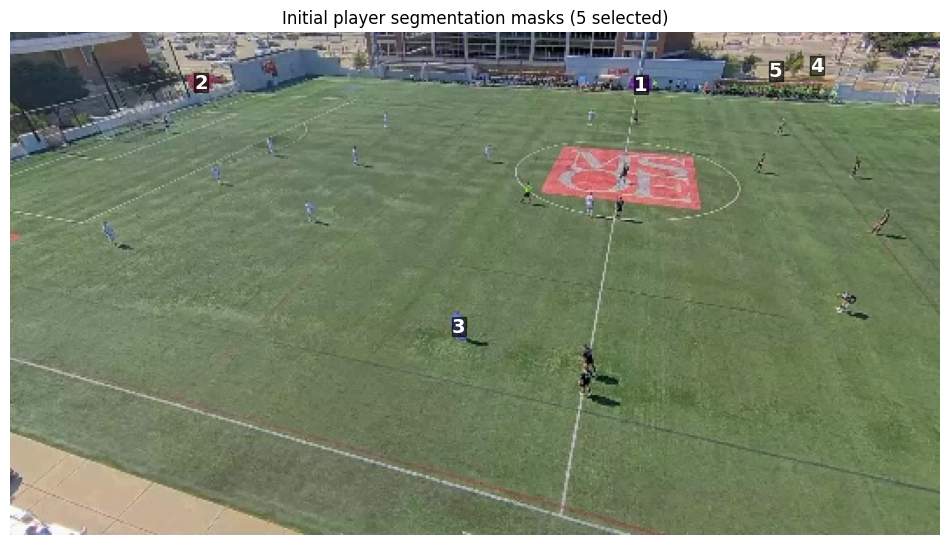

In [18]:
import time
import numpy as np
from sam2.automatic_mask_generator import SAM2AutomaticMaskGenerator
# from pycocotools import mask as mask_util
import matplotlib.pyplot as plt

frame0 = cv2.imread(f"{DOWNSCALED_FRAMES_DIRECTORY}/00000.jpeg")
frame0_rgb = cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB)
h, w = frame0_rgb.shape[:2]
frame_area = h * w

t0 = time.perf_counter()
generator = SAM2AutomaticMaskGenerator(
    model=sam2_model,
    points_per_side=32,
    pred_iou_thresh=0.8,
    stability_score_thresh=0.92,
    min_mask_region_area=100,
)

masks = generator.generate(frame0_rgb)
elapsed = time.perf_counter() - t0
print(f"[BENCH] Auto-segmentation: {len(masks)} masks in {elapsed:.2f}s")

min_frac = 0.00005
max_frac = 0.002

player_masks = []
for m in masks:
    frac = m["area"] / frame_area
    if min_frac <= frac <= max_frac:
        seg = m["segmentation"]
        if isinstance(seg, np.ndarray):
            player_masks.append(seg.astype(bool))

overlay = frame0_rgb.copy()
for mask in player_masks:
    color = np.random.randint(0, 256, size=3, dtype=np.uint8)
    overlay[mask] = ((overlay[mask].astype(np.float32) * 0.5) + (color * 0.5)).astype(np.uint8)

plt.figure(figsize=(12, 7))
plt.imshow(overlay)
for idx, mask in enumerate(player_masks, start=1):
    ys, xs = np.where(mask)
    if ys.size == 0:
        continue
    cx = xs.mean()
    cy = ys.mean()
    plt.text(cx, cy, str(idx), color='white', fontsize=14, weight='bold',
             ha='center', va='center', bbox=dict(facecolor='black', alpha=0.6, pad=0.2))
plt.axis("off")
plt.title(f"Initial player segmentation masks ({len(player_masks)} selected)")
plt.show()

In [ ]:
# Get the center point of the third mask (index 2)
third_mask = player_masks[2]
ys_third, xs_third = np.where(third_mask)
prompt_x = xs_third.mean()
prompt_y = ys_third.mean()

# Create visualization with the prompt point
plt.figure(figsize=(12, 7))
plt.imshow(overlay)

# Draw all player mask centers with numbers
for idx, mask in enumerate(player_masks, start=1):
    ys, xs = np.where(mask)
    if ys.size == 0:
        continue
    cx = xs.mean()
    cy = ys.mean()
    plt.text(cx, cy, str(idx), color='white', fontsize=14, weight='bold',
             ha='center', va='center', bbox=dict(facecolor='black', alpha=0.6, pad=0.2))

# Highlight the prompt point for the third mask
plt.plot(prompt_x, prompt_y, 'r*', markersize=20, label='Prompt point (mask 3)')
plt.legend()
plt.axis("off")
plt.title(f"Prompt point based on third mask center")
plt.show()

print(f"Prompt point for third mask: ({prompt_x:.2f}, {prompt_y:.2f})")